# Sprint 14 — Decomposição do Caso Principal: Olist, recompra de clientes e fatores aliados a retornar ou não

### por Luiz Trajano

---

## O que é este documento

A Olist liga pequenos lojistas de todo o Brasil aos grandes marketplaces com um contrato só. O lojista vende pela loja da Olist nesses canais e despacha o pedido pelos parceiros de logística dela. Depois da entrega, ou quando vence a data prometida, o cliente recebe por e-mail uma pesquisa de satisfação com nota de 1 a 5, um formato comum de avaliação no e-commerce.

A base que uso foi publicada pela própria Olist no [Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): cerca de 100 mil pedidos reais, anonimizados, feitos entre 2016 e 2018. Escolhi estudar a recompra, porque quase todo cliente compra uma vez e não volta (vou verificar na prática): consultarei quantos clientes não voltam depois da primeira compra e o que essa primeira compra teve de diferente para quem voltou, como atraso na entrega, nota baixa, frete caro em relação ao produto ou o estado do cliente.

Com essa resposta, a Olist e os lojistas sabem onde agir na primeira compra para fidelizar o cliente. Os dois podem criar novas políticas juntos, em vez de gastar novamente para trazer um cliente novo.

Este documento é o meu plano, feito antes da análise. Ele vira o Projeto Final, que entrego como notebook, dashboard e relatório para técnicos da área e para pessoas da Olist e dos lojistas.

## Índice

- [0. Setup (diagnóstico inicial)](#0.-Setup-(diagnóstico-inicial))
- [1. O problema de negócio](#1.-O-problema-de-negócio)
- [2. Descrição dos dados](#2.-Descrição-dos-dados)
- [3. Hipóteses](#3.-Hipóteses)
- [4. Indicadores-chave (KPIs)](#4.-Indicadores-chave-(KPIs))
- [5. Ações a executar](#5.-Ações-a-executar)
- [6. Stakeholders impactados](#6.-Stakeholders-impactados)
- [7. Perguntas para o revisor](#7.-Perguntas-para-o-revisor)

---

# 0. Setup (diagnóstico inicial) 

Neste Setup importo as bibliotecas, aplico o meu estilo de gráficos e leio só os 4 arquivos que respondem às perguntas da seção 1.1: `orders`, `customers`, `reviews` e `items`. Cada arquivo fica numa célula com um nome curto, e o `info()` e o `sample()` de cada um dão a primeira vista da base. Depois da leitura, registro o que o `info()` já mostra (tipos e nulos) e analiso onde encontrar os clientes únicos para meus cálculos de recompra, não o cadastro de cada pedido. A limpeza e os números de qualidade ficam para a seção 2. Caso precise de mais bibliotecas ou ajustar ao longo do notebook algo, farei.

### **Arquivos que selecionei da base de dados disponíveis de acordo com as perguntas planejadas:** 

+ `orders` (datas e status dos pedidos: a, e);
+ `customers` (cliente único e estado: d);
+ `reviews` (nota: b, e);
+ `items` (preço e frete: c);

**Obs:** Os outros 5 arquivos da base ficam de fora porque não respondem a nenhuma dessas perguntas.

In [232]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler
from scipy import stats

pd.set_option('display.max_columns', None)

# --- Meu estilo visual (padrão das outras Sprints) ---
meu_estilo = {
    'figure.figsize':   (12, 5),
    'figure.facecolor': '#0d0d0d',
    'axes.facecolor':   '#0d0d0d',
    'savefig.facecolor':'#0d0d0d',
    'axes.edgecolor':   '#333333',
    'axes.labelcolor':  '#aaaaaa',
    'axes.titlecolor':  '#ffffff',
    'text.color':       '#aaaaaa',
    'xtick.color':      '#aaaaaa',
    'ytick.color':      '#aaaaaa',
    'grid.color':       '#222222',
    'axes.grid':        True,
    'axes.grid.axis':   'y',
    'axes.axisbelow':   True,
    'axes.prop_cycle':  cycler(color=['#5B6BF5', '#FF6B6B', '#F5A623', '#4ECDC4', '#C77DFF']),
    'savefig.dpi':      150,
    'savefig.bbox':     'tight',
    'legend.facecolor': '#1a1a1a',
    'legend.edgecolor': '#333333',
}
sns.set_theme(style='dark', rc=meu_estilo)   # seaborn primeiro, meu rc por cima
plt.rcParams.update(meu_estilo)
CORES = ['#5B6BF5', '#FF6B6B', '#F5A623', '#4ECDC4', '#C77DFF']

### Farei a leitura de cada arquivo com o caminho do arquivo no meu notebook/caminho do kaggle para quando rodar na plataforma da Tripleten

### 1. `orders` (olist_orders_dataset.csv)

In [233]:
try:
    orders = pd.read_csv('../04-projeto-final/data/olist_orders_dataset.csv')
except FileNotFoundError:
    # na plataforma não há cópia local: leio direto do Kaggle (o arquivo vem compactado em zip - extraio na leitura)
    orders = pd.read_csv(
        'https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce/olist_orders_dataset.csv',
        compression='zip',
    )

orders.info()
orders.sample(5, random_state=42)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
52263,b9a6c5f5df52c7226ac85aee7524c27f,f160aaf480efdfa7268f0fa535f73e76,delivered,2018-06-12 20:07:44,2018-06-12 20:44:26,2018-06-13 13:09:00,2018-06-19 12:44:08,2018-07-17 00:00:00
46645,261e71d2349c713eafa9f3df5972b95d,d6708bbbd2d419475869a84e41f620a1,delivered,2018-01-20 12:15:57,2018-01-20 12:37:13,2018-01-25 21:42:52,2018-01-30 11:32:35,2018-02-15 00:00:00
37546,67b50899f52995848c427e361e10dde3,1b353c00c71689afba44554e43cc5a76,delivered,2018-06-16 21:24:10,2018-06-16 21:36:59,2018-06-21 13:55:00,2018-06-27 13:17:27,2018-07-16 00:00:00
94756,32733fc014b67ef70fa6039dd8c6ba82,ad66699beab381d0747605f108cc02b4,delivered,2017-08-30 21:12:28,2017-08-31 02:50:24,2017-09-12 20:16:46,2017-09-25 17:53:23,2017-09-22 00:00:00
14771,39a70e9e9b729b11dee34ac12478597f,20c678bfce3c8252288f70dd2bee5e51,delivered,2017-08-10 21:26:25,2017-08-10 21:44:13,2017-08-11 19:11:16,2017-08-22 16:45:00,2017-09-12 00:00:00


### 2. `items` (olist_order_items_dataset.csv)

In [234]:
try:
    items = pd.read_csv('../04-projeto-final/data/olist_order_items_dataset.csv')
except FileNotFoundError:
    # na plataforma não há cópia local: leio direto do Kaggle (o arquivo vem compactado em zip - extraio na leitura)
    items = pd.read_csv(
        'https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv',
        compression='zip',
    )

items.info()
items.sample(5, random_state=42)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
107777,f4ee4273538924bda6212f5948e80fde,1,69455f41626a745aea9ee9164cb9eafd,7d13fca15225358621be4086e1eb0964,2018-06-19 09:18:15,180.00,20.45
2391,056349f85a73d794119c4286c95a52de,1,af35be35db4ad0dc288b571453337376,d20b021d3efdf267a402c402a48ea64b,2017-03-09 14:35:09,10.99,16.05
77829,b124967afcc82ef17ec41020fe2a9136,1,12e6d0f655986ceff00c74658dec97b1,3be634553519fb6536a03e1358e9fdc7,2018-06-06 17:18:09,49.99,8.88
99819,e257ae8610fb4fb68a1f459c3a4b1f51,1,a50acd33ba7a8da8e9db65094fa990a4,8581055ce74af1daba164fdbd55a40de,2017-05-18 08:02:19,117.30,14.43
41297,5e114d8e3840661abc3d9c4820f427b3,1,5cca3efb9521cc1d7099d610d4a12017,3d871de0142ce09b7081e2b9d1733cb1,2018-05-03 18:15:09,58.90,13.77


### 3. `reviews` (olist_order_reviews_dataset.csv)

In [235]:
try:
    reviews = pd.read_csv('../04-projeto-final/data/olist_order_reviews_dataset.csv')
except FileNotFoundError:
    # na plataforma não há cópia local: leio direto do Kaggle (o arquivo vem compactado em zip - extraio na leitura)
    reviews = pd.read_csv(
        'https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv',
        compression='zip',
    )

reviews.info()
reviews.sample(5, random_state=42)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
90252,406e32984dd5273582105460a79571af,e00ed9d20c3479f9f0e9727ca9d60946,5,NaN,NaN,2017-12-22 00:00:00,2017-12-22 21:10:19
24436,3bca8d9922bed47eb96f23d121945290,3b5351f5f99b46339212291661a9d226,5,NaN,Cumpriu o acordado!,2018-04-10 00:00:00,2018-04-13 01:57:05
11313,65895b807ac5dfe062c82400b3f210b8,f395e98fb5c1c6ce1306e80de2fe125b,4,NaN,NaN,2017-04-20 00:00:00,2017-04-21 11:31:32
75442,2a6faa65a6e893105c60b1018d40e14a,57899333b5e286632bd2599d3f7864ce,5,NaN,NaN,2018-04-06 00:00:00,2018-04-07 00:34:14
7217,a738aa683a09dc5979abc7d9c2cc8029,0cc76fbe09687fda664178e9fc6c404f,5,NaN,NaN,2018-01-07 00:00:00,2018-01-08 13:48:20


### 4. `customers` (olist_customers_dataset.csv)

In [236]:
try:
    customers = pd.read_csv('../04-projeto-final/data/olist_customers_dataset.csv')
except FileNotFoundError:
    # na plataforma não há cópia local: leio direto do Kaggle (o arquivo vem compactado em zip - extraio na leitura)
    customers = pd.read_csv(
        'https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce/olist_customers_dataset.csv',
        compression='zip',
    )

customers.info()
customers.sample(5, random_state=42)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
52263,c7432c6d237ffd6aa36a007b4237ec38,9a897ea48bf988012c00b802f1104a92,2971,sao paulo,SP
46645,7f399d641e2e2064470145178c9e8778,90436a67885a57f147fb79e6d0e4bc1c,38610,unai,MG
37546,ba5642b730704dc0f74b7cf715b41ed5,4d8056f71519ae1069e6747c63c676f7,88820,icara,SC
94756,0f346a2cc84ebb2d52f0759d0acfd030,6117c9ef3251089693a6abb90c195eba,25250,duque de caxias,RJ
14771,d393b9491df482cf448e60aa9955b7f2,5caf3a2a5d1ef808e3dd182e79baa392,36955,mutum,MG


In [237]:
# nulos de cada tabela: quantidade e percentual
for nome, tabela in {'orders': orders, 'items': items, 'reviews': reviews, 'customers': customers}.items():
    nulos = tabela.isna().sum()
    nulos = nulos[nulos > 0]
    print(f'--- {nome}')
    if nulos.empty:
        print('sem nulos')
    else:
        print(pd.DataFrame({'nulos': nulos, '%': (nulos / len(tabela) * 100).round(2)}))

--- orders
                               nulos     %
order_approved_at                160  0.16
order_delivered_carrier_date    1783  1.79
order_delivered_customer_date   2965  2.98
--- items
sem nulos
--- reviews
                        nulos      %
review_comment_title    87656  88.34
review_comment_message  58247  58.70
--- customers
sem nulos


**Conclusão 0 — análise prévia dos 4 arquivos:**

+ **orders:** 99.441 pedidos e 8 colunas, todas como `object`, inclusive as 5 de data. Antes de qualquer conta de prazo ou atraso, converto essas datas para `datetime`. Três colunas têm nulos, que vou verificar na seção 2.2: `order_approved_at` (160, 0,16%), `order_delivered_carrier_date` (1.783, 1,79%) e `order_delivered_customer_date` (2.965, 2,98%). Suspeito que sejam pedidos que não chegaram ao fim, como os cancelados. `order_status` pode virar categoria, pois aparenta ter poucos valores possíveis dentro, analiso e converto. 

+ **items:** 112.650 linhas e 7 colunas, sem nulos logo de cara. A data `shipping_limit_date` também está como `object`. Há mais linhas aqui do que pedidos em `orders`, então um pedido pode ter vários itens(o que pode ser normal para esse tipo de venda). Confiro isso na seção 2, antes de juntar as tabelas.

+ **reviews:** 99.224 linhas e 7 colunas. Só as duas colunas de texto das avaliações têm nulos: o título e a mensagem. Faz sentido, porque o comentário é opcional na maioria das vezes, e a nota (`review_score`) está completa. As duas datas também estão como `object`. Há menos linhas do que pedidos em `orders`, então nem todo pedido parece ter avaliação.

+ **customers:** 99.441 linhas e 5 colunas, sem nulos óbvios. O número de linhas é igual ao de pedidos em `orders`, o que indica um `customer_id` por pedido. Por isso a pessoa deve ser o `customer_unique_id`, que confiro logo abaixo. `customer_city` e `customer_state` podem virar categoria, o que ajuda nos agrupamentos por região.

+ **O que levo para a seção 2:** converter as datas, cruzar os nulos de entrega com o status e conferir as chaves repetidas entre as tabelas.

**Obs:** 

Antes de medir a recompra, preciso saber quem é o cliente. Na base, cada pedido gera um `customer_id` novo, mesmo quando a mesma pessoa compra de novo. Quem identifica a pessoa é o `customer_unique_id`.

Para provar isso, faço três passos:

1. Junto `orders` com `customers` pelo `customer_id`, para cada pedido ganhar o `customer_unique_id` da pessoa.
2. Conto quantos pedidos diferentes existem de dois jeitos: por `customer_id` (cadastro) e por `customer_unique_id` (pessoa).
3. Comparo o maior número de pedidos de cada contagem e conto quantas pessoas fizeram mais de um pedido, em número e em percentual.

Se o máximo por `customer_id` for 1, contar por cadastro esconderia toda a recompra, e por isso uso o `customer_unique_id`.

In [238]:
# juntar pedido e cliente com merge
pedidos = orders.merge(customers, on='customer_id')

# pedidos por cadastro (customer_id) e por pessoa (customer_unique_id), usando groupby() e nunique()
por_cadastro = pedidos.groupby('customer_id')['order_id'].nunique()
por_pessoa = pedidos.groupby('customer_unique_id')['order_id'].nunique()

# Mostrando com max() para sabermos o alcance máximo
print(f'máximo de pedidos por customer_id: {por_cadastro.max()}')
print(f'máximo de pedidos por customer_unique_id: {por_pessoa.max()}')
print(f'pessoas com mais de 1 pedido: {(por_pessoa > 1).sum()} ({(por_pessoa > 1).mean():.2%})')

máximo de pedidos por customer_id: 1
máximo de pedidos por customer_unique_id: 17
pessoas com mais de 1 pedido: 2997 (3.12%)


**Conclusão 0.1 — o cliente é o customer_unique_id:**

Contando por `customer_id`, o máximo é 1 pedido: ninguém teria voltado a comprar. Contando por `customer_unique_id`, a mesma pessoa chega a 17 pedidos, e 2.997 pessoas (3,12%) fizeram mais de um. Esse 3,12% ainda é uma medida bruta, porque conta pedidos no mesmo dia e não usa janela de tempo. A definição de recompra que vou usar fica na análise das próximas seções.

---

# 1. O problema de negócio

## 1.1 A pergunta de negócio

### **Pergunta principal:**

O que acontece na primeira compra (entrega, nota, frete e região) que separa o cliente que volta a comprar do que compra uma vez só, e onde a Olist e os lojistas podem agir para que mais clientes voltem?

### **Perguntas derivadas:**

a. O atraso na primeira entrega diminui a chance de o cliente voltar?

b. Uma nota baixa na primeira compra diminui a chance de o cliente voltar?

c. Quando o frete pesa muito no valor do pedido, o cliente volta menos?

d. A chance de o cliente voltar muda conforme o estado em que ele mora?

e. O atraso derruba a nota, e é por causa dessa nota que o cliente não volta? (A pesquisa de satisfação chega quando vence a data prometida, mesmo que o produto ainda não tenha sido entregue.)

Com essas perguntas, digo que decisão a análise apoia.

A análise serve para a Olist e os lojistas escolherem onde agir primeiro para que mais clientes voltem: no prazo de entrega, no pós-venda de quem deu nota baixa, no peso do frete ou em estados específicos. Escolhi a recompra porque ela junta logística, satisfação e preço numa métrica só, e as quatro tabelas que separei medem cada uma dessas partes.

Trato como cliente a pessoa (`customer_unique_id`), não o cadastro de cada pedido (`customer_id`), que muda a cada compra. Se eu contasse por `customer_id`, todo cliente pareceria ter comprado uma vez só.

## 1.2 O setor em poucas linhas

A Olist reúne pequenos lojistas de todo o Brasil e coloca os produtos deles à venda nos grandes marketplaces com um contrato só. O lojista vende pela loja da Olist e despacha o pedido pelos parceiros de logística dela ([descrição do dataset no Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)). Por isso a experiência do cliente depende de dois lados: o lojista, que vende e despacha, e a logística, que entrega.

A base cobre um mercado em crescimento. Em 2018 o e-commerce brasileiro faturou R$ 53,2 bilhões, alta nominal de 12% sobre 2017, com 123 milhões de pedidos (Ebit/Nielsen, Webshoppers, segundo o [Diário do Comércio](https://diariodocomercio.com.br/negocios/comercio-eletronico-no-brasil-faturou-r-532-bilhoes/)).

Num mercado assim, trazer um cliente novo costuma custar mais do que vender de novo para quem já comprou. A estimativa mais citada vai de 5 a 25 vezes, conforme o estudo e o setor ([Gallo, Harvard Business Review, 2014](https://hbr.org/2014/10/the-value-of-keeping-the-right-customers)). É uma faixa larga e não é da Olist: uso só para mostrar a direção do argumento.

## 1.3 Por que isso traz valor

Se a análise mostrar que a recompra cai quando algo acontece na primeira compra, a Olist ganha um lugar claro para agir:

- atraso: avisar o cliente antes de o prazo vencer e cobrar prazo dos lojistas que mais atrasam;
- nota baixa: acionar o pós-venda logo depois de uma nota 1 ou 2;
- atraso que derruba a nota: se a nota baixa vier do atraso, a prioridade é a entrega, não o pós-venda;
- frete pesado: testar frete mais barato ou cupom na segunda compra;
- estado: priorizar a logística nas regiões onde menos gente volta.

Cada ponto percentual a mais na taxa de recompra significa mais 1% dos clientes analisados voltando a comprar. Como a taxa é baixa, um ganho pequeno já é relevante, e o quanto ele representa em clientes depende da coorte que vou definir durante a análise.

---

# 2. Descrição dos dados

## 2.1 Volume

Chamo de volume o tamanho da base: quantas linhas e colunas cada tabela tem, o que uma linha representa e quanto tempo os dados cobrem. Começo por aqui porque todo número que vem depois depende disso. Uma taxa de recompra só faz sentido se eu sei quantos clientes e pedidos existem, em que período, e se estou contando pedidos, itens ou avaliações.

A seguir, junto as quatro tabelas numa visão só. Pedido, item e avaliação não são a mesma coisa, e olhar cada tabela à parte, lado a lado, mostra como elas se encaixam: um pedido pode ter vários itens e nem sempre tem avaliação. Depois olho o período das compras e quantos pedidos a base tem por mês, para ter a ordem de grandeza do movimento da Olist. Comparo a média com a mediana porque os meses quase vazios nas pontas e o crescimento da base podem distorcer a média, e isso decide qual período uso para comparar meses.

In [239]:
# tabela-resumo do volume: linhas, colunas e o que cada linha representa
# a ordem das listas segue a ordem do index (orders, items, reviews, customers)
# Uso len e shape com [1] para selecionar apenas as colunas
volume = pd.DataFrame(
    {
        'linhas': [len(orders), len(items), len(reviews), len(customers)],
        'colunas': [orders.shape[1], items.shape[1], reviews.shape[1], customers.shape[1]],
        'uma linha é': ['um pedido', 'um item de um pedido', 'uma avaliação de um pedido',
                        'o cadastro do cliente em um pedido'],
    },
    index=['orders', 'items', 'reviews', 'customers'],
)
volume

,linhas,colunas,uma linha é
orders,99441,8,um pedido
items,112650,7,um item de um pedido
reviews,99224,7,uma avaliação de um pedido
customers,99441,5,o cadastro do cliente em um pedido


In [240]:
# a data da compra veio como texto: converto para datetime para poder pegar o mês
data_compra = pd.to_datetime(orders['order_purchase_timestamp'])
print(f'primeira compra: {data_compra.min():%d/%m/%Y} | última compra: {data_compra.max():%d/%m/%Y}')

# lista com todos os meses do período, sem pular nenhum
# uso pd.period_range() para gerar todos os meses do período
meses = pd.period_range(data_compra.min(), data_compra.max(), freq='M')

# pedidos por mês; o reindex põe 0 nos meses sem pedido, que o value_counts pularia
pedidos_mes = data_compra.dt.to_period('M').value_counts().reindex(meses, fill_value=0)

# média x mediana: meses vazios e o crescimento da base podem puxar a média
# Exibo ambas e mostro a distribuição completa dos pedidos por mês
print(f'meses cobertos: {len(pedidos_mes)} | meses sem nenhum pedido: {(pedidos_mes == 0).sum()}')
print(f'pedidos por mês: média {pedidos_mes.mean():.0f} | mediana {pedidos_mes.median():.0f}')
print(pedidos_mes)

primeira compra: 04/09/2016 | última compra: 17/10/2018
meses cobertos: 26 | meses sem nenhum pedido: 1
pedidos por mês: média 3825 | mediana 4156
2016-09       4
2016-10     324
2016-11       0
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64


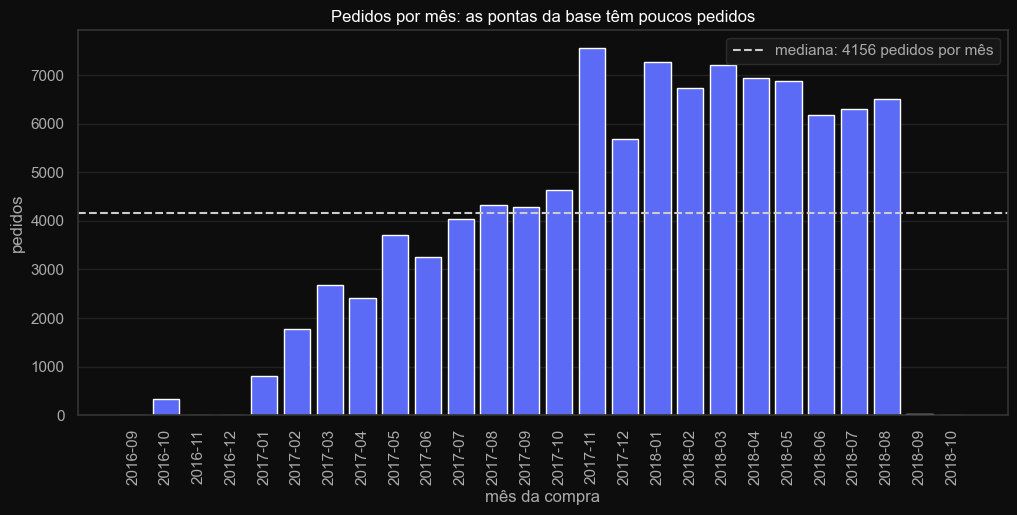

In [241]:
# pasta das imagens criada aqui, na primeira célula que salva gráfico (usarei nas apresentações)
PASTA_IMAGENS = 'images'
os.makedirs(PASTA_IMAGENS, exist_ok=True)

# gráfico dos pedidos por mês, com a mediana como referência
mediana = pedidos_mes.median()
fig, ax = plt.subplots()
ax.bar(pedidos_mes.index.astype(str), pedidos_mes.values, color=CORES[0])
ax.axhline(mediana, color='#cccccc', linestyle='--', label=f'mediana: {mediana:.0f} pedidos por mês')

# título com a conclusão; rótulos do eixo x girados para os 26 meses caberem
# uso o ax.tick_params() para girar os rótulos do eixo x em 90 graus
ax.set_title('Pedidos por mês: as pontas da base têm poucos pedidos')
ax.set_xlabel('mês da compra')
ax.set_ylabel('pedidos')
ax.tick_params(axis='x', rotation=90)
ax.legend()

# salvo antes do show: depois dele a figura sai da memória e a imagem ficaria em branco
plt.savefig(f'{PASTA_IMAGENS}/pedidos_por_mes.png')
plt.show()

In [242]:
# Noto que a base tem fim e início incompletos, com poucos pedidos nos meses extremos
# Ajusto a base de acordo com o período útil definido para ter embasamento de recompra
# Se mantiver o início e o fim da base vou pender para um lado ou outro com números baixos de pedidos
# então defino o período útil:
INICIO_PERIODO_UTIL = '2017-01'
FIM_PERIODO_UTIL = '2018-08'
pedidos_uteis = pedidos_mes.loc[INICIO_PERIODO_UTIL:FIM_PERIODO_UTIL]

# o que muda na média e na mediana, e quanto da base eu perco com o corte
print(f'período útil: {len(pedidos_uteis)} meses | média {pedidos_uteis.mean():.0f} | mediana {pedidos_uteis.median():.0f}')
print(f'pedidos no período útil: {pedidos_uteis.sum()} de {pedidos_mes.sum()} ({pedidos_uteis.sum() / pedidos_mes.sum():.2%})')
print(f'menor mês do período útil: {pedidos_uteis.idxmin()} ({pedidos_uteis.min()} pedidos)')

período útil: 20 meses | média 4955 | mediana 5152
pedidos no período útil: 99092 de 99441 (99.65%)
menor mês do período útil: 2017-01 (800 pedidos)


**Conclusão 2.1 — a base cobre 26 meses, mas só de janeiro de 2017 a agosto de 2018 os meses são comparáveis:**

`orders` tem 99.441 linhas, uma por pedido. `items` tem 112.650, uma por item, então um pedido pode ter mais de um item. `reviews` tem 99.224, uma por avaliação, e `customers` tem 99.441, um cadastro por pedido.

**As pontas.** As compras vão de 04/09/2016 a 17/10/2018. Setembro de 2016 tem 4 pedidos, outubro sobe para 324, e novembro e dezembro caem para 0 e 1. No fim, setembro e outubro de 2018 têm 16 e 4. Isso pode indicar o início da operação dentro da Olist e o corte da extração dos dados, mas os dados não dizem o motivo. A queda para 0 em novembro de 2016, logo depois de outubro, parece uma falha ou pausa na coleta.

**O miolo.** De janeiro de 2017 (800 pedidos) a base cresce até novembro de 2017, o maior mês, com 7.544. Daí até agosto de 2018 ela fica num patamar acima de 6 mil pedidos por mês, com exceção de dezembro de 2017 (5.673).

**Média e mediana.** Na base toda, a média (3.825 pedidos por mês) fica abaixo da mediana (4.156), porque os meses quase vazios das pontas puxam a média para baixo. Para comparar meses, uso de janeiro de 2017 a agosto de 2018: nesse período a média sobe para 4.955 e a mediana para 5.152, e mantenho 99.092 dos 99.441 pedidos (99,65%), ou seja, o corte quase não reduz a base. A média continua um pouco abaixo da mediana, principalmente pelo crescimento da base ao longo de 2017.

**O que isso ainda não resolve.** O período útil serve para comparar meses, mas não resolve a recompra. Quem fez a primeira compra em julho ou agosto de 2018 está dentro do período, e mesmo assim teve poucas semanas para voltar antes de a base acabar. Contar essas pessoas faria a recompra parecer menor do que é. Por isso, na seção 4, defino uma janela de dias e uso só clientes cuja primeira compra deixa essa janela inteira dentro da base.

## 2.2 Qualidade

Aqui confiro se os dados estão prontos para medir a recompra. Os nulos já apareceram no Setup (Conclusão 0). Agora vejo o que eles significam e procuro outros problemas: linhas e chaves repetidas, datas fora de ordem e valores impossíveis em preço, frete e nota. Para cada problema, separo o que é erro do que é característica do dado, porque só o erro pede limpeza.

In [243]:
# 1. linhas inteiras repetidas: duplicated() marca a linha igual a uma anterior
# verifico para cada csv que tenho
# Uso for para minimizar repetição de código
tabelas = {'orders': orders, 'items': items, 'reviews': reviews, 'customers': customers}
for nome, tabela in tabelas.items():
    print(f'{nome}: {tabela.duplicated().sum()} linhas duplicadas\n')

# 2. chaves repetidas: a linha pode ser diferente e a chave se repetir
# orders e customers deveriam ter 1 linha por chave; reviews pode ter mais de 1 avaliação por pedido
chaves = [('orders', 'order_id'), ('customers', 'customer_id'),
        ('reviews', 'order_id'), ('reviews', 'review_id')]
# Novamente uso for para minimizar repetição de código
for nome, coluna in chaves:
    repetidos = tabelas[nome][coluna].duplicated()
    print(f'{nome}.{coluna}: {repetidos.sum()} repetidos ({repetidos.mean():.2%})')

orders: 0 linhas duplicadas

items: 0 linhas duplicadas

reviews: 0 linhas duplicadas

customers: 0 linhas duplicadas

orders.order_id: 0 repetidos (0.00%)
customers.customer_id: 0 repetidos (0.00%)
reviews.order_id: 551 repetidos (0.56%)
reviews.review_id: 814 repetidos (0.82%)


In [244]:
# 3. Vou ver agora os nulos da data de entrega por order_status no dataframe orders
# pd.crosstab: cruza duas colunas e conta quantos pedidos caem em cada combinação
# isna() marca True onde falta a data; o map troca True/False por 'sem data'/'com data'
# assim separo pedido não entregue (característica) de pedido entregue sem data (erro)
pd.crosstab(
    orders['order_status'],
    orders['order_delivered_customer_date'].isna().map({False: 'com data', True: 'sem data'}),
)

# 4. datas fora de ordem: converto as 4 etapas do pedido para datetime e comparo uma com a outra
etapas = ['order_purchase_timestamp', 'order_approved_at',
        'order_delivered_carrier_date', 'order_delivered_customer_date']

# apply(pd.to_datetime) converte cada uma das 4 colunas de texto para data, de uma vez
# o resultado vai para datas: orders continua intacto
datas = orders[etapas].apply(pd.to_datetime)

# cada regra marca True quando uma etapa acontece antes da anterior
# uno cada parte das datas e verifico se alguma regra de ordem foi violada
regras = {
    'aprovado antes da compra': datas['order_approved_at'] < datas['order_purchase_timestamp'],
    'enviado antes da aprovação': datas['order_delivered_carrier_date'] < datas['order_approved_at'],
    'entregue antes do envio': datas['order_delivered_customer_date'] < datas['order_delivered_carrier_date'],
    'entregue antes da compra': datas['order_delivered_customer_date'] < datas['order_purchase_timestamp'],
}
for regra, fora_de_ordem in regras.items():
    print(f'{regra}: {fora_de_ordem.sum()} pedidos ({fora_de_ordem.mean():.2%})')

aprovado antes da compra: 0 pedidos (0.00%)
enviado antes da aprovação: 1359 pedidos (1.37%)
entregue antes do envio: 23 pedidos (0.02%)
entregue antes da compra: 0 pedidos (0.00%)


In [245]:
# 5. valores que não podem existir: preço <= 0, frete < 0 e review_score fora de 1 a 5
# freight_value == 0 entra na lista, mas não conta como erro: pode ser frete grátis
# cada condição vira True/False por linha: sum() dá o total e mean() o percentual
checagens = {
    'price <= 0': items['price'] <= 0,
    'freight_value < 0': items['freight_value'] < 0,
    'freight_value == 0': items['freight_value'] == 0,
    'review_score fora de 1 a 5': ~reviews['review_score'].between(1, 5), #uso between para verificar o intervalo
}
for regra, condicao in checagens.items():
    print(f'{regra}: {condicao.sum()} ({condicao.mean():.2%})')

price <= 0: 0 (0.00%)
freight_value < 0: 0 (0.00%)
freight_value == 0: 383 (0.34%)
review_score fora de 1 a 5: 0 (0.00%)


In [246]:
# 6. review_id repetido: a mesma avaliação cobre pedidos de uma pessoa só? Me questionei isso vendo os dados
# pego só as linhas com review_id repetido e trago a pessoa e a data de compra de cada pedido
# Assim posso compreender melhor
rev_rep = reviews[reviews['review_id'].duplicated(keep=False)]
rev_rep = (rev_rep
        .merge(orders[['order_id', 'customer_id', 'order_purchase_timestamp']], on='order_id')
        .merge(customers[['customer_id', 'customer_unique_id']], on='customer_id'))

# converto a data da compra para datetime e normalize() zera a hora: sobra só o dia
# a coluna nova fica em rev_rep, então orders continua intacto
rev_rep['dia_compra'] = pd.to_datetime(rev_rep['order_purchase_timestamp']).dt.normalize()

# por review_id: quantas pessoas, quantas notas e quantos dias de compra diferentes
por_review = rev_rep.groupby('review_id').agg(
    pessoas=('customer_unique_id', 'nunique'),
    notas=('review_score', 'nunique'),
    dias=('dia_compra', 'nunique'),
)

# eq(1) é o mesmo que == 1: compara cada valor com 1 e devolve True/False por review_id
# True = o review_id tem uma pessoa só (ou uma nota só, ou um dia só)
# sum() conta os True (total) e mean() dá a proporção de True (percentual)
print(f'review_id repetidos: {len(por_review)}')
for coluna, texto in [('pessoas', 'de uma pessoa só'), ('notas', 'com uma nota só'), ('dias', 'com pedidos no mesmo dia')]:
    so_um = por_review[coluna].eq(1)
    print(f'{texto}: {so_um.sum()} ({so_um.mean():.2%})')

review_id repetidos: 789
de uma pessoa só: 789 (100.00%)
com uma nota só: 789 (100.00%)
com pedidos no mesmo dia: 748 (94.80%)


**Conclusão 2.2 — os problemas de qualidade são pequenos e nenhum impede responder às perguntas:**

**Duplicados.** Nenhuma tabela tem linha inteira repetida, e `order_id` em `orders` e `customer_id` em `customers` são únicos. A repetição aparece só nas chaves de `reviews`: o `order_id` se repete em 551 linhas (0,56%), então há pedido com mais de uma avaliação, e o `review_id` se repete em 814 linhas (0,82%).

**Avaliação repetida.** As 814 repetições vêm de 789 avaliações que cobrem mais de um pedido. Todas são de uma pessoa só e com uma nota só, e 748 delas (94,80%) juntam pedidos feitos no mesmo dia. Não são avaliações diferentes da mesma pessoa: é uma opinião só, registrada em vários pedidos. Parece uma compra dividida em vários pedidos que recebeu uma pesquisa só, mas os dados não dizem o motivo. Isso não atrapalha a nota, que ligo ao pedido pelo `order_id`. E mostra que pedidos no mesmo dia não devem contar como recompra, o que levo para a definição da seção 4.

**Nulos de entrega.** Quase todo pedido sem data de entrega não foi entregue: são cancelados (619), enviados que ainda não chegaram (1.107), indisponíveis (609), faturados (314) e em processamento (301). Isso é característica, não erro. Os erros são 8 pedidos `delivered` sem data e 6 `canceled` com data. Como a pergunta a é sobre a primeira entrega, planejo calcular o atraso só com pedidos entregues e com data, deixando os 8 de fora.

**Datas fora de ordem.** Nenhum pedido foi aprovado nem entregue antes da compra. Há 1.359 pedidos (1,37%) enviados à transportadora antes da aprovação e 23 (0,02%) entregues antes do envio. Os dados não dizem o motivo. Essas etapas intermediárias não entram no atraso, que compara a entrega ao cliente com a data estimada, então não mudam as perguntas.

**Valores.** Nenhum preço é zero ou negativo, nenhum frete é negativo e todas as notas estão entre 1 e 5. Há 383 itens (0,34%) com frete zero, provavelmente frete grátis. Planejo mantê-los: na pergunta c, eles entram com peso do frete igual a zero.

**O que vai para a seção 5.(Execução de ações)** Converter as datas para `datetime`, manter uma avaliação por pedido, calcular o atraso só com pedidos entregues com data e manter o frete zero.

## 2.3 Resumo estatístico

Aqui resumo as variáveis que entram nas perguntas, sem tratar nada. Para preço e frete (pergunta c) e nota (pergunta b) uso o `describe()` e comparo média com mediana para ver se há assimetria. Calculo o prazo de entrega e o atraso em relação à data estimada só para descrever a pergunta a, com as datas convertidas em variáveis à parte. Depois mostro as frequências de status, nota e estado (pergunta d) e quantos pedidos cada pessoa fez, que é a distribuição central da recompra, e quanto tempo quem volta leva para a segunda compra, que define a janela da seção 4. Os dois gráficos têm o mesmo formato, então uso uma função chamada num laço.

In [247]:
# 1. resumo das numéricas das perguntas: price e freight_value (c) e review_score (b)
# concat junta os dois describe() lado a lado, um por coluna
resumo = pd.concat([items[['price', 'freight_value']].describe(),
                    reviews['review_score'].describe()], axis=1).round(2)
resumo

,price,freight_value,review_score
count,112650.00,112650.00,99224.00
mean,120.65,19.99,4.09
std,183.63,15.81,1.35
min,0.85,0.00,1.00
25%,39.90,13.08,4.00
50%,74.99,16.26,5.00
75%,134.90,21.15,5.00
max,6735.00,409.68,5.00


In [248]:
# 2. prazo de entrega e atraso (pergunta a), só com pedidos delivered que têm data de entrega
# Uso novamente o eq para comparar strings, neste caso para filtrar pedidos com status 'delivered'
# Também uso notnull() para garantir que a data de entrega não seja nula
entregues = orders[orders['order_status'].eq('delivered') & orders['order_delivered_customer_date'].notnull()]

# datas convertidas em variáveis à parte: orders continua intacto (a conversão definitiva fica na 5.1)
compra = pd.to_datetime(entregues['order_purchase_timestamp'])
entrega = pd.to_datetime(entregues['order_delivered_customer_date'])
estimada = pd.to_datetime(entregues['order_estimated_delivery_date'])

# prazo = entrega - compra; atraso = entrega - estimada, com normalize() porque a estimada não tem hora
prazo_dias = (entrega - compra).dt.days
atraso_dias = (entrega.dt.normalize() - estimada).dt.days

# atraso > 0 marca o pedido que chegou depois da data estimada
atrasados = atraso_dias > 0
print(f'pedidos entregues com data: {len(entregues)}')
print(f'entregues depois da data estimada: {atrasados.sum()} ({atrasados.mean():.2%})')
pd.DataFrame({'prazo de entrega (dias)': prazo_dias,
            'atraso em relação à estimativa (dias)': atraso_dias}).describe().round(1)

pedidos entregues com data: 96470
entregues depois da data estimada: 6534 (6.77%)


,prazo de entrega (dias),atraso em relação à estimativa (dias)
count,96470.0,96470.0
mean,12.1,-11.9
std,9.6,10.2
min,0.0,-147.0
25%,6.0,-17.0
50%,10.0,-12.0
75%,15.0,-7.0
max,209.0,188.0


In [249]:
# 3. frequências das categóricas: order_status, review_score (pergunta b) e customer_state (pergunta d)
# qtd = value_counts(): quantas linhas têm cada valor
# % = ...(normalize=True) * 100: a fatia de cada valor no total da tabela
# o % é calculado antes do head(10), então os estados mostram a fatia sobre a base inteira

frequencias = {'order_status': orders['order_status'],
            'review_score': reviews['review_score'],
            'customer_state': customers['customer_state']}
for nome, serie in frequencias.items():
    tabela = pd.DataFrame({'qtd': serie.value_counts(),
                           '%': (serie.value_counts(normalize=True) * 100).round(2)})
    if nome == 'review_score':
        tabela = tabela.sort_index()
    elif nome == 'customer_state':
        tabela = tabela.head(10)
    print(f'--- {nome}')
    print(tabela)

--- order_status
                qtd      %
order_status              
delivered     96478  97.02
shipped        1107   1.11
canceled        625   0.63
unavailable     609   0.61
invoiced        314   0.32
processing      301   0.30
created           5   0.01
approved          2   0.00
--- review_score
                qtd      %
review_score              
1             11424  11.51
2              3151   3.18
3              8179   8.24
4             19142  19.29
5             57328  57.78
--- customer_state
                  qtd      %
customer_state              
SP              41746  41.98
RJ              12852  12.92
MG              11635  11.70
RS               5466   5.50
PR               5045   5.07
SC               3637   3.66
BA               3380   3.40
DF               2140   2.15
ES               2033   2.04
GO               2020   2.03


In [250]:
# 4. pedidos por pessoa: a distribuição central da recompra (por_pessoa vem da Conclusão 0.1)
# pd.cut separa em faixas pelos limites de bins: (0, 1] = 1 pedido, (1, 2] = 2 pedidos, (2, máximo] = 3 ou mais
faixa = pd.cut(por_pessoa, bins=[0, 1, 2, por_pessoa.max()],
            labels=['1 pedido', '2 pedidos', '3 ou mais'])

# value_counts conta as pessoas em cada faixa; sort_index mantém a ordem das faixas
contagem_faixa = faixa.value_counts().sort_index().rename_axis('pedidos por pessoa')
pd.DataFrame({'pessoas': contagem_faixa,
              '%': (contagem_faixa / contagem_faixa.sum() * 100).round(2)})

,pessoas,%
pedidos por pessoa,,
1 pedido,93099,96.88
2 pedidos,2745,2.86
3 ou mais,252,0.26


In [251]:
# Crio um parametro para poder medir o tempo até a segunda compra, só para quem voltou em outro dia 
# (define a janela da seção 4)
# pedidos vem da Conclusão 0.1 (orders + customers); a data vira datetime sem a hora
# preciso dessa etapa para ajudar nos KPIs
compras = pedidos[['customer_unique_id', 'order_purchase_timestamp']].copy()
compras['dia_compra'] = pd.to_datetime(compras['order_purchase_timestamp']).dt.normalize()

# um dia por pessoa: pedidos no mesmo dia contam como uma compra só (seção 2.2)
dias_compra = (compras[['customer_unique_id', 'dia_compra']].drop_duplicates()
            .sort_values(['customer_unique_id', 'dia_compra']))

# cumcount numera as compras de cada pessoa em ordem de data: 0 = primeira, 1 = segunda
# não tinha usado cumcount antes, mas aqui é útil para numerar as compras de cada pessoa
# incremento pois agrega muito e enriquece o meu conhecimento de formas novas
dias_compra['ordem'] = dias_compra.groupby('customer_unique_id').cumcount()
primeira = dias_compra[dias_compra['ordem'] == 0].set_index('customer_unique_id')['dia_compra']
segunda = dias_compra[dias_compra['ordem'] == 1].set_index('customer_unique_id')['dia_compra']

# dias entre a primeira e a segunda compra, só de quem tem segunda compra
intervalo = (segunda - primeira.loc[segunda.index]).dt.days
print(f'pessoas que voltaram em outro dia: {len(intervalo)}')
print(f'dias até a segunda compra: média {intervalo.mean():.0f} | mediana {intervalo.median():.0f} | máximo {intervalo.max()}')

# quanto das voltas cada janela candidata cobre
for janela in [90, 180, 365]:
    coberto = intervalo <= janela
    print(f'janela de {janela} dias: {coberto.sum()} voltas ({coberto.mean():.2%})')

pessoas que voltaram em outro dia: 2149
dias até a segunda compra: média 114 | mediana 72 | máximo 609
janela de 90 dias: 1195 voltas (55.61%)
janela de 180 dias: 1634 voltas (76.04%)
janela de 365 dias: 2059 voltas (95.81%)


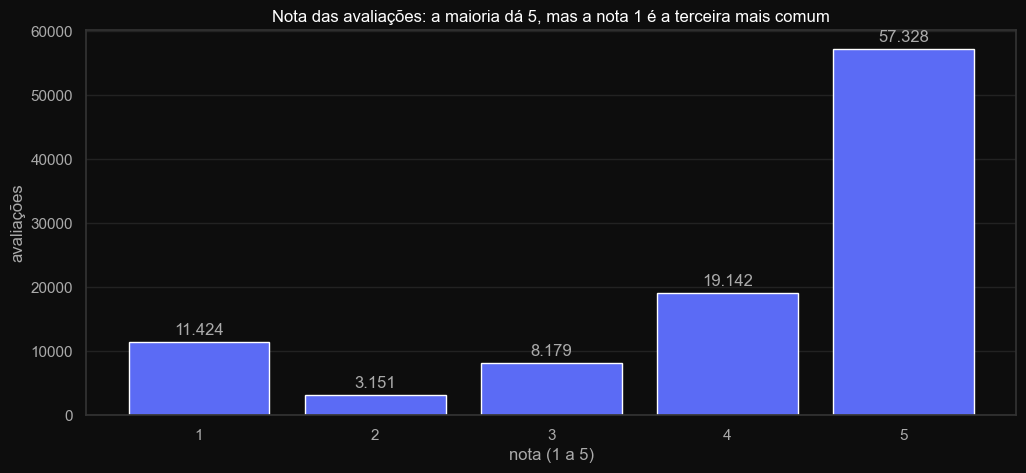

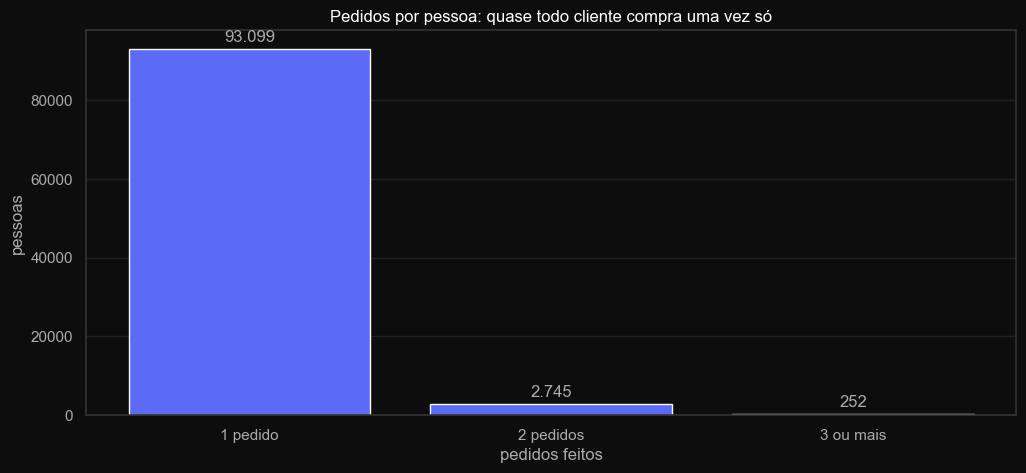

In [252]:
def plotar_barras(contagem, titulo, rotulo_x, rotulo_y, arquivo):
    """Desenha um gráfico de barras com a quantidade em cima de cada barra e salva em PASTA_IMAGENS.

    Parâmetros
    ----------
    contagem : Series com as categorias no índice e as quantidades nos valores.
    titulo : título do gráfico, escrito como conclusão.
    rotulo_x : nome do eixo x.
    rotulo_y : nome do eixo y, com a unidade.
    arquivo : nome do arquivo .png salvo em PASTA_IMAGENS.

    Retorna
    -------
    None : salva e mostra o gráfico.
    """
    fig, ax = plt.subplots()
    barras = ax.bar(contagem.index.astype(str), contagem.values, color=CORES[0])
    # rótulo em cima de cada barra, com ponto como separador de milhar
    ax.bar_label(barras, labels=[f'{valor:,}'.replace(',', '.') for valor in contagem.values],
                color='#aaaaaa', padding=3)
    ax.set_title(titulo)
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel(rotulo_y)
    plt.savefig(f'{PASTA_IMAGENS}/{arquivo}')
    plt.show()


# 6. um gráfico por pergunta: a nota (b) e os pedidos por pessoa (o problema da recompra)
graficos = [
    (reviews['review_score'].value_counts().sort_index(),
    'Nota das avaliações: a maioria dá 5, mas a nota 1 é a terceira mais comum',
    'nota (1 a 5)', 'avaliações', 'notas.png'),
    (contagem_faixa,
    'Pedidos por pessoa: quase todo cliente compra uma vez só',
    'pedidos feitos', 'pessoas', 'pedidos_por_pessoa.png'),
]
for contagem, titulo, rotulo_x, rotulo_y, arquivo in graficos:
    plotar_barras(contagem, titulo, rotulo_x, rotulo_y, arquivo)

**Conclusão 2.3 — quase todo cliente compra uma vez só, e as variáveis das perguntas são assimétricas:**

**Preço e frete (pergunta c).** O preço por item tem média de R$ 120,65 e mediana de R$ 74,99. O frete tem média de R$ 19,99 e mediana de R$ 16,26. Nos dois a média fica acima da mediana, e o máximo passa muito do 3º quartil (R$ 6.735,00 contra R$ 134,90 no preço; R$ 409,68 contra R$ 21,15 no frete): poucos itens caros puxam a média. Por isso, nas comparações, planejo olhar a mediana e usar testes que não supõem distribuição normal.

**Prazo e atraso (pergunta a).** Entre os 96.470 pedidos entregues com data, o prazo mediano é de 10 dias (média de 12,1). A entrega costuma chegar antes da data estimada: na mediana, 12 dias antes (na média, 11,9 dias antes). Mesmo assim, 6.534 pedidos (6,77%) chegaram depois da data estimada, e é esse grupo que a pergunta a compara com o resto.

**Nota (pergunta b).** A nota tem média de 4,09 e mediana de 5. A maioria dá 5 (57.328 avaliações, 57,78%), mas a nota 1 é a terceira mais comum (11.424, 11,51%), à frente das notas 3 e 2. Há um grupo grande de clientes insatisfeitos para comparar com o resto.

**Status e estado (pergunta d).** 96.478 pedidos (97,02%) estão como `delivered`. SP concentra 41.746 pedidos (41,98%), seguido de RJ (12,92%) e MG (11,70%), e o 10º estado (GO) já tem só 2,03%, com os demais abaixo disso. Estados pequenos vão ter poucos clientes, então planejo agrupá-los na pergunta d.

**Pedidos por pessoa.** 93.099 pessoas (96,88%) fizeram 1 pedido, 2.745 (2,86%) fizeram 2 e 252 (0,26%) fizeram 3 ou mais. É a imagem do problema: quem volta é um grupo pequeno, o que bate com os 3,12% brutos da Conclusão 0.1. Com um grupo tão raro, toda comparação vai mostrar a diferença absoluta e a relativa juntas.

**Tempo até a segunda compra.** Das pessoas que voltaram em outro dia (2.149), a média até a segunda compra é de 114 dias e a mediana de 72, com máximo de 609: poucas demoram muito e puxam a média. Por isso não uso a média para a janela, e sim quanto das voltas cada janela cobre: 90 dias pegam 1.195 voltas (55,61%), 180 dias pegam 1.634 (76,04%) e 365 dias pegam 2.059 (95,81%). Escolho 180 dias (seção 4): cobre 3 de cada 4 voltas sem encolher demais a coorte, o que aconteceria com 365 dias. Esses intervalos também sofrem com o fim da base, porque quem comprou pela primeira vez em 2018 só pode aparecer com intervalos curtos, então a cobertura real tende a ser um pouco menor.

In [253]:
# Crio um parametro para poder medir o tempo até a segunda compra, só para quem voltou em outro dia
# pedidos vem da Conclusão 0.1 (orders + customers); a data vira datetime sem a hora~
# Preciso disso aqui para ajudar a criar os KPIS e direcionar a busca de clientes recorrentes
compras = pedidos[['customer_unique_id', 'order_purchase_timestamp']].copy()
compras['dia_compra'] = pd.to_datetime(compras['order_purchase_timestamp']).dt.normalize()

# um dia por pessoa: pedidos no mesmo dia contam como uma compra só (seção 2.2)
dias_compra = (compras[['customer_unique_id', 'dia_compra']].drop_duplicates()
            .sort_values(['customer_unique_id', 'dia_compra']))

# cumcount numera as compras de cada pessoa em ordem de data: 0 = primeira, 1 = segunda
# não tinha usado cumcount antes, mas aqui é útil para numerar as compras de cada pessoa
# incremento pois agrega muito e enriquece o meu conhecimento de formas novas
dias_compra['ordem'] = dias_compra.groupby('customer_unique_id').cumcount()
primeira = dias_compra[dias_compra['ordem'] == 0].set_index('customer_unique_id')['dia_compra']
segunda = dias_compra[dias_compra['ordem'] == 1].set_index('customer_unique_id')['dia_compra']

# dias entre a primeira e a segunda compra, só de quem tem segunda compra
intervalo = (segunda - primeira.loc[segunda.index]).dt.days
print(f'pessoas que voltaram em outro dia: {len(intervalo)}')
print(f'dias até a segunda compra: média {intervalo.mean():.0f} | mediana {intervalo.median():.0f}')

# quanto das voltas cada janela candidata cobre
for janela in [90, 180, 365]:
    coberto = intervalo <= janela
    print(f'janela de {janela} dias: {coberto.sum()} voltas ({coberto.mean():.2%})')

pessoas que voltaram em outro dia: 2149
dias até a segunda compra: média 114 | mediana 72
janela de 90 dias: 1195 voltas (55.61%)
janela de 180 dias: 1634 voltas (76.04%)
janela de 365 dias: 2059 voltas (95.81%)


## 2.4 Como as tabelas se ligam

Aqui mostro como as quatro tabelas se ligam antes de juntar qualquer uma. O `order_id` liga `orders`, `items` e `reviews`, o `customer_id` liga `orders` a `customers`, e o `customer_unique_id` identifica a pessoa. Confiro quantos itens os pedidos têm, se há pedidos sem item ou sem avaliação, e o que acontece se eu juntar as tabelas direto. A armadilha que evito é a multiplicação de linhas: um pedido com três itens viraria três linhas e contaria três vezes.

In [254]:
# um pedido pode ter vários itens: o order_id se repete em items
print(f"items: {len(items)} linhas para {items['order_id'].nunique()} pedidos")

# pedidos de orders sem nenhum item e sem nenhuma avaliação: isin() procura o order_id na outra tabela
for nome, tabela in {'items': items, 'reviews': reviews}.items():
    sem_registro = ~orders['order_id'].isin(tabela['order_id'])
    print(f'pedidos sem registro em {nome}: {sem_registro.sum()} ({sem_registro.mean():.2%})')

# juntarei direto, sem agregar antes, multiplico as linhas
# merge com how='left' mantém todos os pedidos de orders, mesmo sem item ou sem avaliação
# cada item e cada avaliação a mais vira uma linha a mais do mesmo pedido
juntado = orders.merge(items, on='order_id', how='left').merge(reviews, on='order_id', how='left')
linhas_a_mais = len(juntado) - len(orders)
print(f'orders: {len(orders)} linhas | depois do merge com items e reviews: {len(juntado)} '
    f'({linhas_a_mais} a mais, {linhas_a_mais / len(orders):.2%})')

items: 112650 linhas para 98666 pedidos
pedidos sem registro em items: 775 (0.78%)
pedidos sem registro em reviews: 768 (0.77%)
orders: 99441 linhas | depois do merge com items e reviews: 114092 (14651 a mais, 14.73%)


**Conclusão 2.4 — as tabelas se ligam pelo pedido, e juntar sem agregar antes infla a base:**

| Ligação | Chave | Relação |
|---|---|---|
| `orders` e `customers` | `customer_id` | 1 pedido para 1 cadastro |
| `orders` e `items` | `order_id` | 1 pedido para nenhum, 1 ou mais itens |
| `orders` e `reviews` | `order_id` | 1 pedido para nenhuma, 1 ou mais avaliações |
| `customers` e a pessoa | `customer_unique_id` | 1 pessoa para 1 ou mais cadastros |

**Itens.** `items` tem 112.650 linhas para 98.666 pedidos, então parte dos pedidos tem mais de um item.

**Pedidos sem par.** 775 pedidos (0,78%) não têm nenhum item e 768 (0,77%) não têm avaliação. Sem item não há preço nem frete, e esses pedidos ficam fora da pergunta c. Sem avaliação não há nota, e eles ficam fora das perguntas b e e.

**Multiplicação de linhas.** Juntar `orders` com `items` e `reviews` direto leva a base de 99.441 para 114.092 linhas, 14.651 a mais (14,73%). Cada pedido com vários itens ou várias avaliações passaria a contar mais de uma vez. Por isso planejo, na seção 5.1, agregar `items` e `reviews` por pedido antes de qualquer junção.

## 2.5 Variáveis-chave

Aqui reúno as variáveis que respondem às perguntas da seção 1.1. Separo três papéis: chave (liga tabelas ou identifica quem conto), métrica (o que meço) e variável que vou criar no Projeto Final a partir das outras. Cada uma aponta a pergunta que responde, para não entrar variável sem uso.

| Variável | Tabela | Papel | Por que importa para a recompra |
|---|---|---|---|
| `customer_unique_id` | `customers` | chave de agregação | identifica a pessoa; a recompra é contada por ela (Conclusão 0.1) |
| `customer_id` | `orders`, `customers` | chave de ligação | liga o pedido ao cadastro e, por ele, à pessoa |
| `order_id` | `orders`, `items`, `reviews` | chave de ligação | liga o pedido aos itens e à avaliação (seção 2.4) |
| `order_purchase_timestamp` | `orders` | métrica de tempo | define a primeira compra, a volta e a coorte (seção 4) |
| `order_status` | `orders` | filtro | o atraso usa só pedidos `delivered` com data (seção 2.2) |
| `order_delivered_customer_date` | `orders` | métrica de tempo | data em que o cliente recebeu (perguntas a e e) |
| `order_estimated_delivery_date` | `orders` | métrica de tempo | data prometida, base do atraso (perguntas a e e) |
| `review_score` | `reviews` | métrica | nota da primeira compra (perguntas b e e) |
| `review_answer_timestamp` | `reviews` | critério | quando o pedido tem mais de uma avaliação, fica a primeira resposta: é a mais próxima da primeira entrega e evita usar nota dada depois de uma recompra (seção 2.2) |
| `price` | `items` | métrica | valor dos produtos do pedido (pergunta c) |
| `freight_value` | `items` | métrica | frete do pedido (pergunta c) |
| `customer_state` | `customers` | chave de agregação | estado do cliente, agrupado se tiver poucos clientes (pergunta d) |
| voltou a comprar | criada | variável-alvo | sim se a pessoa fez outro pedido, em outro dia, dentro da janela (seção 4) |
| atraso em dias | criada | métrica | entrega ao cliente menos data estimada, com datas normalizadas (pergunta a) |
| atrasou | criada | grupo | sim se o atraso em dias for maior que 0 (perguntas a e e) |
| grupo de nota | criada | grupo | nota da primeira compra em três grupos: muito baixa (1), baixa (2 e 3) e alta (4 e 5, referência) (perguntas b e e) |
| peso do frete | criada | métrica | frete do pedido dividido pelo valor dos produtos do pedido (pergunta c) |

---

# 3. Hipóteses

Cada hipótese sai de uma pergunta da seção 1.1 e olha só o que aconteceu na **primeira compra** de cada pessoa. Usar dado de um pedido posterior seria explicar a volta com algo que veio depois dela. A recompra é rara (cerca de 3% brutos, Conclusão 0.1), então toda comparação mostra a diferença em pontos percentuais e a diferença relativa juntas, além do p-valor.

| # | Hipótese (proposta concreta) | H0 / H1 | Como testo | KPI usado |
|---|---|---|---|---|
| H1 (a) | Quem recebe a primeira compra atrasada volta menos. Se for verdade, a Olist deve priorizar prazo e avisar o cliente antes de o prazo vencer. | H0: a taxa de recompra de quem teve atraso é igual à de quem não teve. H1: é diferente. | Teste z de proporções entre os dois grupos (atrasou sim/não): a variável é binária (voltou ou não), os grupos são independentes e grandes. | Taxa de recompra por grupo de atraso |
| H2 (b) | Quem dá nota baixa na primeira compra volta menos, e menos ainda com nota 1. Se for verdade, o pós-venda deve agir logo depois de uma nota de 1 a 3. | H0: a taxa de recompra é igual nos três grupos de nota. H1: pelo menos um grupo é diferente. | Qui-quadrado nos três grupos (muito baixa, baixa, alta). Se rejeitar H0, z de proporções de cada grupo de nota baixa contra a nota alta, com correção de Holm para as 2 comparações. | Taxa de recompra por grupo de nota |
| H3 (c) | Quem paga um frete pesado em relação ao produto volta menos. Se for verdade, frete mais barato ou cupom na segunda compra podem trazer o cliente de volta. | H0: o peso do frete na primeira compra tem a mesma distribuição para quem volta e para quem não volta. H1: é diferente. | Mann-Whitney, porque o peso do frete é assimétrico (seção 2.3) e não supõe distribuição normal. Para leitura de negócio, mostro também a taxa de recompra por faixa de peso do frete (quartis). | Peso do frete; taxa de recompra por faixa de peso do frete |
| H4 (d) | A recompra muda conforme o estado do cliente. Se for verdade, a logística deve priorizar os estados onde menos gente volta. | H0: a taxa de recompra é igual em todos os grupos de estado. H1: pelo menos um grupo é diferente. | Qui-quadrado com os estados que têm pelo menos 5% dos pedidos separados (SP, RJ, MG, RS e PR, seção 2.3) e os demais juntos em "outros", porque estados pequenos têm poucos clientes. O limite de 5% fica numa constante na célula do teste. Se rejeitar H0, z de proporções entre os grupos, com correção de Holm. | Taxa de recompra por grupo de estado |
| H5 (e) | O atraso reduz a recompra porque derruba a nota. Se for verdade, corrigir a entrega vem antes de reforçar o pós-venda. | Parte 1. H0: a proporção de nota de 1 a 3 é igual entre quem teve atraso e quem não teve. H1: é diferente. Parte 2. H0: dentro de cada grupo de nota, a recompra de quem teve atraso é igual à de quem não teve. H1: é diferente. | Parte 1: z de proporções. Parte 2: z de proporções dentro de cada grupo de nota, com correção de Holm. Se o efeito do atraso some quando a nota é a mesma, é a nota que explica a volta. | Proporção de nota de 1 a 3 por grupo de atraso; taxa de recompra por atraso dentro de cada grupo de nota |

**Regras para todos os testes.** Nível de significância de 5%, declarado antes de rodar e guardado numa constante (`ALFA`) na célula dos testes, normalmente usado como o padrão e vou seguir. A correção de Holm vale dentro de cada hipótese que tem mais de uma comparação. Os dados são observacionais: um resultado significativo mostra associação, não prova que a ação traz o cliente de volta. Não rejeitar H0 também não prova que não há efeito, porque o grupo que volta é pequeno, e por isso olho o tamanho da diferença junto com o p-valor.

---

# 4. Indicadores-chave (KPIs)

Antes das fórmulas, fecho as duas definições de que todo KPI depende. Cada uma vira uma constante nomeada na célula onde for usada no Projeto Final.

**Quem é o cliente.** A pessoa (`customer_unique_id`), não o cadastro do pedido (Conclusão 0.1).

**O que é recompra.** Um novo pedido da mesma pessoa, feito em **outro dia** e até `JANELA_RECOMPRA_DIAS` dias depois da primeira compra. Pedido no mesmo dia não conta, porque a seção 2.2 mostrou que a mesma compra pode virar vários pedidos no mesmo dia. A janela é de 180 dias: ela cobre 76,04% das voltas em outro dia, contra 55,61% com 90 dias, e com 365 dias a coorte ficaria só com as primeiras compras até agosto de 2017 (seção 2.3).

**Quem entra na conta (coorte).** Só pessoas cuja primeira compra deixa a janela inteira dentro do período útil da seção 2.1 (`INICIO_PERIODO_UTIL` a `FIM_PERIODO_UTIL`). A data de corte é:

```
DATA_CORTE_COORTE = FIM_PERIODO_UTIL - JANELA_RECOMPRA_DIAS
```

Quem comprou pela primeira vez depois dessa data fica de fora, porque não teve tempo de voltar.

---

**1. Taxa de recompra (KPI principal).** Mede quantas pessoas voltam. É o número que a Olist quer aumentar.

```
recompra = pessoas da coorte com outro pedido, em outro dia, dentro da janela
          / pessoas da coorte
```

Alerta: não uso um valor de mercado, porque não achei referência confiável para este caso. A referência é a própria taxa da coorte. Um grupo é "ruim" quando a recompra dele fica abaixo da referência com diferença significativa no teste da seção 3.

**2. Recompra por grupo e diferença em relação à referência.** Usada em todas as hipóteses (H1 a H5). Para um grupo g (por exemplo, "atrasou") e o grupo de referência r (por exemplo, "não atrasou"):

```
recompra_g = pessoas do grupo g que voltaram / pessoas do grupo g
```

```
diferenca_absoluta = recompra_g - recompra_r                  (em pontos percentuais)
diferenca_relativa = (recompra_g - recompra_r) / recompra_r   (em %)
```

Mostro as duas juntas, porque com uma recompra perto de 3% uma diferença relativa grande pode ser poucos clientes em número absoluto.

**3. Taxa de atraso na primeira compra (H1 e H5).** Mede quantas primeiras entregas chegaram depois do prometido.

```
taxa_atraso = primeiras compras entregues depois da data estimada
              / primeiras compras entregues com data
```

O pedido atrasou quando a data de entrega, sem a hora, é posterior à data estimada. Alerta: a taxa de atraso de todos os pedidos entregues é de 6,77% (seção 2.3). Uma taxa acima disso na coorte, ou num estado, indica entrega pior que a média da base.

**4. Proporção de nota baixa na primeira compra (H2 e H5).** Mede a insatisfação.

```
nota_baixa = primeiras compras com nota de 1 a 3 / primeiras compras com avaliação
```

A nota 1 também é medida sozinha, porque é o grupo "muito baixa" da H2. Na H5, comparo essa proporção entre quem teve atraso e quem não teve.

**5. Peso do frete na primeira compra (H3).** Mede o quanto o frete pesa no que o cliente paga.

```
peso_frete = soma de freight_value dos itens do pedido
             / soma de price dos itens do pedido
```

Somo por pedido antes de dividir, porque um pedido pode ter vários itens (seção 2.4). Não há limiar fixo: comparo a distribuição de quem volta com a de quem não volta (Mann-Whitney) e mostro a recompra por quartil de peso do frete.

---

# 5. Ações a executar

## 5.1 Preparação e tratamento dos dados

O objetivo da preparação é chegar a uma base com **uma linha por pessoa da coorte**, com os atributos da primeira compra e a resposta "voltou ou não". Cada passo resolve um problema encontrado na seção 2:

1. **Datas.** Converter as datas de `orders` e `reviews` de texto para `datetime` (Conclusão 0).
2. **Pessoa.** Juntar `orders` e `customers` pelo `customer_id`, que é uma ligação de 1 para 1 (seção 2.4), para cada pedido ganhar o `customer_unique_id`.
3. **Primeira compra.** Para cada pessoa, a primeira compra é o primeiro dia com pedido. Pedidos no mesmo dia contam como uma compra só (seção 2.2), e os atributos desse dia são somados: preço e frete somam, o atraso vale se algum pedido do dia atrasou e a nota é a menor do dia.
4. **Recompra e coorte.** Criar `voltou_a_comprar`: outro pedido, em outro dia, até `JANELA_RECOMPRA_DIAS = 180` dias depois da primeira compra (seção 4). Manter só pessoas com primeira compra entre `INICIO_PERIODO_UTIL` e `DATA_CORTE_COORTE`.
5. **Itens.** Agregar `items` por pedido antes de juntar (seção 2.4): soma de `price`, soma de `freight_value` e número de itens. Criar `peso_frete`. O frete zero fica, como frete grátis (seção 2.2). Pedidos sem item ficam fora da pergunta c.
6. **Avaliações.** Manter uma avaliação por pedido, a de primeira resposta (`review_answer_timestamp`, seção 2.5), e criar o grupo de nota: muito baixa (1), baixa (2 e 3) e alta (4 e 5). Pedidos sem avaliação ficam fora das perguntas b e e.
7. **Atraso.** Calcular `atraso_dias` só com pedidos `delivered` com data de entrega, comparando as datas sem a hora. Os 8 `delivered` sem data ficam de fora (seção 2.2). Criar `atrasou` (atraso maior que 0).
8. **Estado.** Agrupar os estados com menos de 5% dos pedidos em "outros" (seção 3, H4), com o limite numa constante.
9. **Conferência.** Depois de cada junção, conferir que o número de linhas não cresceu, e que a base final tem uma linha por pessoa.

## 5.2 Análise dos dados

Cada análise responde a uma pergunta da seção 1.1. Todas usam a base por pessoa da 5.1 e mostram o número absoluto e o percentual juntos.

| Análise | Pergunta | Saída |
|---|---|---|
| Taxa de recompra da coorte e por mês da primeira compra | principal | tabela e gráfico de linha por mês |
| Recompra de quem teve atraso contra quem não teve | a | tabela e gráfico de barras |
| Recompra por grupo de nota (muito baixa, baixa, alta) | b | tabela e gráfico de barras |
| Peso do frete de quem voltou contra quem não voltou, e recompra por quartil de peso do frete | c | boxplot e gráfico de barras |
| Recompra por grupo de estado | d | tabela e gráfico de barras |
| Proporção de nota de 1 a 3 por grupo de atraso, e recompra por atraso dentro de cada grupo de nota | e | tabela cruzada e gráfico de barras agrupadas |

Os gráficos repetem o mesmo formato, então uso uma função com docstring chamada num laço. As cores ficam fixas em todo o projeto: quem voltou em azul (`#5B6BF5`), quem não voltou em vermelho (`#FF6B6B`), e referências em cinza. A base por pessoa, com as variáveis da seção 2.5, é salva para o dashboard, onde farei no tableau, para os números baterem com o notebook.

## 5.3 Validação das hipóteses

Os testes estão descritos na seção 3. Aqui fica o porquê de cada método com estes dados:

- **Teste z de proporções (H1, H2, H4 e H5).** A resposta é binária (voltou ou não), os grupos são independentes, porque cada pessoa entra uma vez só, e grandes o bastante para a aproximação normal.
- **Qui-quadrado (H2 e H4).** Quando o atributo tem mais de dois grupos, testa primeiro se há alguma diferença, antes das comparações dois a dois. Isso evita fazer muitas comparações sem necessidade.
- **Mann-Whitney (H3).** O peso do frete é assimétrico (seção 2.3), então comparo as distribuições sem supor normalidade, em vez de comparar médias com teste t.
- **Correção de Holm.** Toda hipótese com mais de uma comparação usa Holm, para o risco de falso positivo não crescer com o número de testes. É menos conservadora que Bonferroni e controla o mesmo erro.
- **Nível de significância.** 5%, declarado antes de rodar, numa constante `ALFA` na célula dos testes.
- **Tamanho do efeito.** Todo resultado mostra a diferença em pontos percentuais e a relativa (seção 4), além do p-valor. Como quem volta é um grupo pequeno, confiro também se os grupos têm tamanho para detectar uma diferença que importe para o negócio, antes de concluir que não há efeito.
- **Limite.** Os dados são observacionais. Um resultado significativo mostra associação, não que a ação vai trazer o cliente de volta.

## 5.4 Comunicação dos resultados

**Dashboard.** Feito no Tableau Public, porque abre pelo link, sem conta corporativa, tanto para o revisor quanto para a Olist ou quem quiser verificar a análise. Ele foi pensado para as áreas que vão agir com o resultado (gestão, CRM, logística e o time que acompanha os lojistas) e mostra:

1. a taxa de recompra da coorte e a evolução por mês da primeira compra;
2. a recompra por atraso, por grupo de nota e por faixa de peso do frete;
3. a recompra por estado, em mapa ou barras.

Os filtros são o mês da primeira compra, o grupo de estado, o grupo de nota e o atraso (sim ou não). A base vem do notebook (seção 5.2), para os números baterem.

**Relatório final.** Em PDF, no formato CAR, curto e para quem não é técnico e para quem é também:

- **Contexto:** o problema da recompra, por que importa e as cinco hipóteses.
- **Ações:** os dados usados, a definição de recompra, a preparação e os testes.
- **Resultados:** o que se confirmou, o tamanho de cada efeito e as recomendações, em ordem de prioridade.

Dashboard e relatório usam a mesma paleta escura e as mesmas cores do notebook. Os links dos dois vão numa célula Markdown no topo do notebook do Projeto Final, testados numa janela anônima.

## 5.5 Estimativa de tempo (duas semanas)

| Etapa | Dias úteis | Entrega |
|---|---|---|
| Preparação dos dados e base por pessoa (5.1) | 2 | base da coorte com uma linha por pessoa, conferida |
| Análise exploratória da recompra (5.2) | 1 | taxas e gráficos de cada pergunta |
| Validação das hipóteses (5.3) | 2 | H1 a H5 testadas, com conclusão em cada uma |
| Dashboard (5.4) | 0,5 | link publicado no Tableau Public |
| Relatório final CAR (5.4) | 0,5 | PDF com link |
| Revisão e ajustes | 0,5 | notebook rodando do zero e links testados |
| **Total** | **6,5** | |

O total fica abaixo das duas semanas do enunciado, e a folga cobre imprevistos e os ajustes pedidos na revisão. O dashboard e o relatório começam assim que a base por pessoa estiver pronta, em paralelo com a validação, e não só no fim.

---

# 6. Stakeholders impactados

| Papel ou área | O que muda para eles | Por que foram escolhidos |
|---|---|---|
| Logística e operações | prioridade de prazo e aviso de atraso ao cliente | o atraso é a H1 e a H5 |
| Atendimento e pós-venda | contato logo depois de uma nota de 1 a 3 | a nota é a H2 e a H5 |
| Gestão dos lojistas | cobrança de prazo de despacho dos lojistas que mais atrasam | o lojista despacha o pedido (seção 1.2) |
| CRM e marketing | campanhas de segunda compra, como cupom de frete | a recompra é o KPI principal e o frete é a H3 |
| Liderança da Olist | escolha de onde investir primeiro | a análise ordena as ações pelo tamanho do efeito |

---

# 7. Perguntas para o revisor

1. A definição de recompra (outro pedido, em outro dia, até 180 dias depois da primeira compra, só na coorte com a janela inteira) é adequada ou devo usar média ou mediana como o real parametro?
2. Quando a primeira compra tem vários pedidos no mesmo dia, uso a pior nota e conto atraso se algum pedido atrasou. Essa regra é aceitável ou é preferível não considerar este dia?
3. Na H5, comparar a recompra por atraso dentro de cada grupo de nota é suficiente, ou é esperado um modelo, como regressão logística?
4. Na plataforma, a leitura dos CSVs pelo link do Kaggle é aceita, ou devo subir os arquivos de outra forma?
5. Criei argumentos e perguntas demais ou segui uma boa linha pra analisar agora, após vossa revisão?